In [1]:
# ====================================
# Import libraries
# ====================================
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import random_split, DataLoader
import torchvision.transforms.v2 as T
from torch.utils.data import TensorDataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

"""
This code has been used to test different possible CNNs settings.
We tried different depths (Experiment 1), initial weights (Experiment 2), learning rates (Experiment 3),
number of epochs (Experiment 4), and batch sizes (Experiment 5).
The best CNN found with this code, has then been used for all the 3 parts of task2.
"""

'\nThis code has been used to test different possible CNNs settings.\nWe tried different depths (Experiment 1), initial weights (Experiment 2), learning rates (Experiment 3),\nnumber of epochs (Experiment 4), and batch sizes (Experiment 5).\nThe best CNN found with this code, has then been used for all the 3 parts of task2.\n'

In [3]:
#Check whether a GPU is available
print("GPU available:", torch.cuda.is_available())

#Check which GPU is being used
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

GPU available: True
GPU name: Tesla T4


In [4]:
# ====================================
# Reproducibility and device
# ====================================
r_seed = 99
generator = torch.Generator()

def reset_seed(seed=r_seed):
    """Reset all seeds at once."""
    random.seed(seed) #reset python random seed
    np.random.seed(seed) #reset numpy random seed
    torch.manual_seed(seed) #reset pytorch random seed
    generator.manual_seed(seed) #reset the dataloader random seed
    if torch.cuda.is_available(): #if we use the gpu
        torch.cuda.manual_seed_all(seed)

reset_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
#This cell runs on Google Colab if you save the data files in a folder called "data" in Drive.
#To run locally, skip this cell and set the paths to data/075_images.npy

from google.colab import drive
drive.mount('/content/drive')

In [5]:
# ====================================
# Load the Clock dataset (75x75)
# ====================================
images_path = '/content/drive/MyDrive/DL_Assignment_1/data/075_images.npy'
labels_path = '/content/drive/MyDrive/DL_Assignment_1/data/075_labels.npy'

images_np = np.load(images_path)
labels_np = np.load(labels_path)

#Check out our images
print("images:", images_np.shape, images_np.dtype, images_np.min(), images_np.max()) #18'000 images, 75x75
print("labels:", labels_np.shape, labels_np.dtype) #18'000 labels, 2 dimensions (hour, min)
print("hours:", np.unique(labels_np[:, 0])) #they go from 0 to 11
print("minutes:", labels_np[:, 1].min(), labels_np[:, 1].max()) #they go from 0 to 59

#Convert into pytorch tensors
images = torch.from_numpy(images_np).float() #turn numpy array into pytorch tensor, float
images = images.unsqueeze(1) #add channel dimension, we need format (batch_size, channels, height, width) (greyscale = 1 channel)
mean = images.mean()
std = images.std()
images = (images - mean) / std #standardize the pixels (easier for training)

labels_minutes = torch.from_numpy(labels_np[:, 0] * 60 + labels_np[:, 1]).long() #hours*60 + minutes, and turn it into pytorch tensor
print(labels_minutes.shape, labels_minutes.min(), labels_minutes.max()) #18'000 labels, 1 dimension (min). Minutes go from 0 (00:00) to 719 (11:59).

images: (18000, 75, 75) uint8 16 255
labels: (18000, 2) int64
hours: [ 0  1  2  3  4  5  6  7  8  9 10 11]
minutes: 0 59
torch.Size([18000]) tensor(0) tensor(719)


In [6]:
#=====================================
# Train-Validation-Test split
# ====================================
reset_seed()

dataset = TensorDataset(images, labels_minutes)
n = len(dataset)

train_size = int(0.8 * n)
valid_size = int(0.1 * n)
test_size = n - train_size - valid_size

train_data, valid_data, test_data = random_split(
    dataset,
    [train_size, valid_size, test_size],
    generator=generator
)

batch_size = 64

train_dataloader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

valid_dataloader = DataLoader(
    valid_data,
    batch_size=batch_size,
    shuffle=True
)

test_dataloader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=True
)

In [7]:
# ======================================================
# Defining the functions for training and evaluation
# ======================================================


#Train the model

def train_model(model, train_dataloader, optimizer, criterion, epochs, bin_size):

    """Train a model for a given number of epochs."""

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        for inputs, minutes in train_dataloader:

            #data agumentation
            #inputs = train_transform(inputs)

            #To use external GPU
            inputs = inputs.to(device)
            minutes = minutes.to(device)

            #convert the labels from labels in minutes (e.g., 01:30 --> 90 minutes) to labels in classes (e.g., class 3)
            labels_class = (minutes // bin_size).long()

            #zero the parameter gradients
            optimizer.zero_grad()

            #forward + backward + optimize
            outputs = model(inputs) #predictions
            loss = criterion(outputs, labels_class) #compute loss
            loss.backward() #compute gradients
            optimizer.step() #optimize weights

            #compute running loss
            running_loss += loss.item()
        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"- Loss = {running_loss/len(train_dataloader):.4f}"
        )

#Validate the model

def evaluate_model(model, dataloader, bin_size):

    """Evaluate a model using the average circular time error."""

    model.eval()

    total_error = 0
    total = 0

    with torch.no_grad():
        for inputs, minutes in dataloader:

            #To use external GPU
            inputs = inputs.to(device)
            minutes = minutes.to(device)

            #Get predictions and classes
            outputs = model(inputs) #predictions (in classes!!!)
            predictions = outputs.argmax(dim=1) #assign to the class with the highest score

            #Convert predicted classes back into total minutes
            predicted_minutes = predictions * bin_size + (bin_size - 1) / 2 #midpoint to represent the class

            #Calculate absolute difference and the circular difference
            difference = torch.abs(predicted_minutes - minutes)
            circular_difference = torch.minimum(difference, 720 - difference)

            #Compute the errors
            total_error += circular_difference.sum().item()
            total += minutes.size(0)

    common_sense_error = total_error / total

    return common_sense_error

In [8]:
# =====================================
# Trying out different CNNs
# =====================================

class Net_2conv(nn.Module):   #baseline: task1_CNN, plus padding=1, and one less fully connected layer
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 3, padding=1)
        self.fc1 = nn.Linear(16 * 18 * 18, 120)
        self.fc2 = nn.Linear(120, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


class Net_3conv(nn.Module):   #Add one convolutional layer
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 9 * 9, 120)
        self.fc2 = nn.Linear(120, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


class Net_4conv(nn.Module):   #Add another convolutional layer
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv4 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [9]:
# =====================================
# Trying out different initial weights
# =====================================
def init_he(module):
    """He weight initialisation""" #this is made for ReLU
    if isinstance(module, (nn.Linear, nn.Conv2d)):
        nn.init.kaiming_normal_(module.weight, nonlinearity="relu")
        nn.init.zeros_(module.bias) #biases start at 0

def init_xavier(module):
    """Xavier (Glorot) initialisation""" #this is what the book introduced (dive into deep learning)
    if isinstance(module, (nn.Linear, nn.Conv2d)):
        nn.init.xavier_uniform_(module.weight)
        nn.init.zeros_(module.bias) #biases start at 0

In [10]:
# =====================================
# Run experiment function
# =====================================

#One function to be able to run the different experiments by changing one setting at a time
def run_experiment(NetClass, seed, init_fn=None, bin_size=30, epochs=20, lr=0.001, batch_size=64):

    #New seed for each experiment
    reset_seed(seed)

    #The training loader is built here, so that we can change the batch size
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, generator=generator)

    num_classes = 720 // bin_size
    model = NetClass(num_classes).to(device)

    #Initialization weights
    if init_fn is not None:
        model.apply(init_fn)

    #Loss function
    criterion = nn.CrossEntropyLoss()

    #Optimizer
    optimizer = optim.Adam(model.parameters(), lr=lr)

    #Train the model
    train_model(model, train_loader, optimizer, criterion, epochs, bin_size)

    #Validate the model
    return evaluate_model(model, valid_dataloader, bin_size)

In [11]:
# =====================================
# Experiment 1: depth of the CNN
# =====================================
nets = {"Net_2conv": Net_2conv, "Net_3conv": Net_3conv, "Net_4conv": Net_4conv}

#We run each experiment is run 3 times, so that the results are not due to random luck
seeds = [1, 2, 3]

rows = []
for name, NetClass in nets.items():
    for seed in seeds:
        err = run_experiment(NetClass, seed)
        rows.append({"net": name, "seed": seed, "common_sense_error": err})

depth_df = pd.DataFrame(rows)
print(depth_df)
print(depth_df.groupby("net")["common_sense_error"].agg(["mean", "std"]))

Epoch 1/20: - Loss = 3.1798
Epoch 2/20: - Loss = 2.9807
Epoch 3/20: - Loss = 2.4097
Epoch 4/20: - Loss = 2.0793
Epoch 5/20: - Loss = 1.8681
Epoch 6/20: - Loss = 1.7314
Epoch 7/20: - Loss = 1.5817
Epoch 8/20: - Loss = 1.4692
Epoch 9/20: - Loss = 1.3723
Epoch 10/20: - Loss = 1.2648
Epoch 11/20: - Loss = 1.1793
Epoch 12/20: - Loss = 1.0892
Epoch 13/20: - Loss = 1.0302
Epoch 14/20: - Loss = 0.9640
Epoch 15/20: - Loss = 0.9033
Epoch 16/20: - Loss = 0.8506
Epoch 17/20: - Loss = 0.8125
Epoch 18/20: - Loss = 0.7755
Epoch 19/20: - Loss = 0.7221
Epoch 20/20: - Loss = 0.6723
Epoch 1/20: - Loss = 3.1760
Epoch 2/20: - Loss = 2.8421
Epoch 3/20: - Loss = 2.1747
Epoch 4/20: - Loss = 1.7452
Epoch 5/20: - Loss = 1.4234
Epoch 6/20: - Loss = 1.1595
Epoch 7/20: - Loss = 0.9507
Epoch 8/20: - Loss = 0.7766
Epoch 9/20: - Loss = 0.6329
Epoch 10/20: - Loss = 0.5212
Epoch 11/20: - Loss = 0.4268
Epoch 12/20: - Loss = 0.3454
Epoch 13/20: - Loss = 0.2965
Epoch 14/20: - Loss = 0.2475
Epoch 15/20: - Loss = 0.1912
Epo

In [12]:
# =====================================
# Experiment 2: initial weights (on Net_4conv)
# =====================================
inits = {"default": None, "xavier": init_xavier, "he": init_he}
seeds = [1, 2, 3]

rows = []
for init_name, init_fn in inits.items():
    for seed in seeds:
        err = run_experiment(Net_4conv, seed, init_fn=init_fn)
        rows.append({"init": init_name, "seed": seed, "common_sense_error": err})

init_df = pd.DataFrame(rows)
print(init_df)
print(init_df.groupby("init")["common_sense_error"].agg(["mean", "std"]))

Epoch 1/20: - Loss = 3.1794
Epoch 2/20: - Loss = 3.1780
Epoch 3/20: - Loss = 2.9351
Epoch 4/20: - Loss = 2.1525
Epoch 5/20: - Loss = 1.6315
Epoch 6/20: - Loss = 1.2926
Epoch 7/20: - Loss = 1.0274
Epoch 8/20: - Loss = 0.8571
Epoch 9/20: - Loss = 0.7299
Epoch 10/20: - Loss = 0.6340
Epoch 11/20: - Loss = 0.5556
Epoch 12/20: - Loss = 0.4794
Epoch 13/20: - Loss = 0.4371
Epoch 14/20: - Loss = 0.4128
Epoch 15/20: - Loss = 0.3659
Epoch 16/20: - Loss = 0.3168
Epoch 17/20: - Loss = 0.2981
Epoch 18/20: - Loss = 0.2977
Epoch 19/20: - Loss = 0.2569
Epoch 20/20: - Loss = 0.2412
Epoch 1/20: - Loss = 3.1792
Epoch 2/20: - Loss = 3.0314
Epoch 3/20: - Loss = 2.2519
Epoch 4/20: - Loss = 1.6990
Epoch 5/20: - Loss = 1.3349
Epoch 6/20: - Loss = 1.0878
Epoch 7/20: - Loss = 0.8961
Epoch 8/20: - Loss = 0.7527
Epoch 9/20: - Loss = 0.6618
Epoch 10/20: - Loss = 0.5705
Epoch 11/20: - Loss = 0.5043
Epoch 12/20: - Loss = 0.4520
Epoch 13/20: - Loss = 0.4008
Epoch 14/20: - Loss = 0.3631
Epoch 15/20: - Loss = 0.3401
Epo

In [13]:
# =====================================
# Experiment 3: learning rate (on Net_4conv, default weights)
# =====================================

#Here we use only one seed because in early runs we saw that the differences were large enough to be distinguished without
#averaging over 3 seeds' results.
#Here we use again more epochs (40), because smaller learning rates learn more slowly, and might need more epochs

seed = 1 #one fixed seed for every learning rate

rows = []
for lr in [0.003, 0.001, 0.0003]:
    err = run_experiment(Net_4conv, seed, init_fn=None, epochs=40, lr=lr)
    rows.append({"lr": lr, "seed": seed, "common_sense_error": err})
    print(f"lr={lr}: {err:.2f} min")

lr_df = pd.DataFrame(rows)
print(lr_df)

Epoch 1/40: - Loss = 3.1795
Epoch 2/40: - Loss = 3.1788
Epoch 3/40: - Loss = 3.1787
Epoch 4/40: - Loss = 3.1787
Epoch 5/40: - Loss = 3.1788
Epoch 6/40: - Loss = 3.1787
Epoch 7/40: - Loss = 3.1787
Epoch 8/40: - Loss = 3.1787
Epoch 9/40: - Loss = 3.1787
Epoch 10/40: - Loss = 3.1788
Epoch 11/40: - Loss = 3.1788
Epoch 12/40: - Loss = 3.1787
Epoch 13/40: - Loss = 3.1787
Epoch 14/40: - Loss = 3.1787
Epoch 15/40: - Loss = 3.1788
Epoch 16/40: - Loss = 3.1787
Epoch 17/40: - Loss = 3.1788
Epoch 18/40: - Loss = 3.1787
Epoch 19/40: - Loss = 3.1786
Epoch 20/40: - Loss = 3.1786
Epoch 21/40: - Loss = 3.1787
Epoch 22/40: - Loss = 3.1786
Epoch 23/40: - Loss = 3.1787
Epoch 24/40: - Loss = 3.1787
Epoch 25/40: - Loss = 3.1788
Epoch 26/40: - Loss = 3.1787
Epoch 27/40: - Loss = 3.1787
Epoch 28/40: - Loss = 3.1787
Epoch 29/40: - Loss = 3.1787
Epoch 30/40: - Loss = 3.1787
Epoch 31/40: - Loss = 3.1787
Epoch 32/40: - Loss = 3.1786
Epoch 33/40: - Loss = 3.1788
Epoch 34/40: - Loss = 3.1787
Epoch 35/40: - Loss = 3

In [14]:
# =====================================
# Experiment 4: number of epochs and plot the learning curves
# =====================================

#We use Net_4conv, default weights, lr = 0.001, 30-minute bins, 1 seed
#Here we use more epochs because we want to see where we can stop

def train_validate_curves(NetClass, seed, bin_size=30, epochs=50, lr=0.001):
    reset_seed(seed)
    num_classes = 720 // bin_size
    model = NetClass(num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses, valid_losses, valid_errors = [], [], []
    for epoch in range(epochs):
        #training
        model.train()
        running_loss = 0.0
        for inputs, minutes in train_dataloader:
            inputs, minutes = inputs.to(device), minutes.to(device)
            labels_class = (minutes // bin_size).long()
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels_class)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        train_losses.append(running_loss / len(train_dataloader))

        #validation loss (no learning here)
        model.eval()
        running_loss = 0.0
        with torch.no_grad():
            for inputs, minutes in valid_dataloader:
                inputs, minutes = inputs.to(device), minutes.to(device)
                labels_class = (minutes // bin_size).long()
                running_loss += criterion(model(inputs), labels_class).item()
        valid_losses.append(running_loss / len(valid_dataloader))

        #validation common-sense error (the metric we really care about)
        valid_errors.append(evaluate_model(model, valid_dataloader, bin_size))

        print(f"Epoch {epoch + 1}/{epochs}: train loss = {train_losses[-1]:.4f}, "
              f"valid loss = {valid_losses[-1]:.4f}, valid error = {valid_errors[-1]:.2f} min")

    return model, train_losses, valid_losses, valid_errors


epochs = 50
model, train_losses, valid_losses, valid_errors = train_validate_curves(Net_4conv, seed=1, epochs=epochs)


Epoch 1/50: train loss = 3.1793, valid loss = 3.1801, valid error = 176.41 min
Epoch 2/50: train loss = 3.1787, valid loss = 3.1781, valid error = 182.66 min
Epoch 3/50: train loss = 3.1533, valid loss = 3.0482, valid error = 153.53 min
Epoch 4/50: train loss = 2.5966, valid loss = 2.2936, valid error = 101.95 min
Epoch 5/50: train loss = 2.0453, valid loss = 1.8958, valid error = 78.66 min
Epoch 6/50: train loss = 1.6852, valid loss = 1.6562, valid error = 63.72 min
Epoch 7/50: train loss = 1.4396, valid loss = 1.3983, valid error = 51.98 min
Epoch 8/50: train loss = 1.2332, valid loss = 1.2090, valid error = 44.75 min
Epoch 9/50: train loss = 1.1062, valid loss = 1.1630, valid error = 38.45 min
Epoch 10/50: train loss = 0.9753, valid loss = 1.0661, valid error = 35.62 min
Epoch 11/50: train loss = 0.8820, valid loss = 0.9820, valid error = 33.08 min
Epoch 12/50: train loss = 0.8233, valid loss = 0.9098, valid error = 30.41 min
Epoch 13/50: train loss = 0.7567, valid loss = 0.9346, va

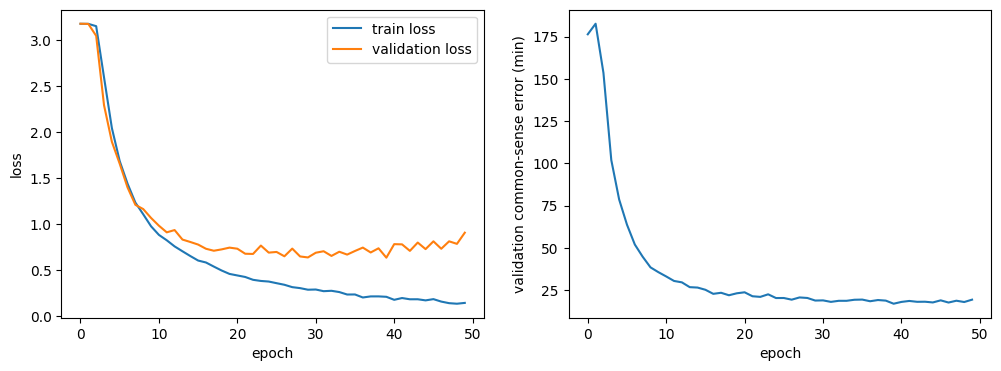

after 20 epochs: validation error = 23.11 minutes
after 30 epochs: validation error = 18.81 minutes
after 40 epochs: validation error = 16.94 minutes
after 50 epochs: validation error = 19.34 minutes


In [15]:
#Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_losses, label="train loss")
axes[0].plot(valid_losses, label="validation loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
axes[1].plot(valid_errors)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation common-sense error (min)")
plt.show()

#Error after 20, 30, 40 and 50 epochs
for e in [20, 30, 40, 50]:
    print(f"after {e} epochs: validation error = {valid_errors[e - 1]:.2f} minutes")

In [16]:
# =====================================
# Experiment 5: batch size
# =====================================

#We want to check if different batch sizes (on Net_4conv, default weights, lr = 0.001) can improve the model.
#Here we go back to using 20 epochs, because hopefully it's enough to see which setting performs best

batch_sizes = [32, 64, 128]
seeds = [1, 2, 3]
rows = []

for batch_size_test in batch_sizes:
    for seed in seeds:
        err = run_experiment(Net_4conv, seed, batch_size=batch_size_test)
        rows.append({"batch_size": batch_size_test, "seed": seed, "common_sense_error": err})

batch_df = pd.DataFrame(rows)
print(batch_df)
print(batch_df.groupby("batch_size")["common_sense_error"].agg(["mean", "std"]))

#NB.
#Batch 32 is slightly better but not enough. Since it would be slower to train, we keep batch 64.

Epoch 1/20: - Loss = 3.1793
Epoch 2/20: - Loss = 3.1776
Epoch 3/20: - Loss = 3.1786
Epoch 4/20: - Loss = 3.1786
Epoch 5/20: - Loss = 3.1785
Epoch 6/20: - Loss = 3.1785
Epoch 7/20: - Loss = 3.1785
Epoch 8/20: - Loss = 3.1784
Epoch 9/20: - Loss = 3.1784
Epoch 10/20: - Loss = 3.1784
Epoch 11/20: - Loss = 3.1784
Epoch 12/20: - Loss = 3.1783
Epoch 13/20: - Loss = 3.1783
Epoch 14/20: - Loss = 3.1784
Epoch 15/20: - Loss = 3.1784
Epoch 16/20: - Loss = 3.1783
Epoch 17/20: - Loss = 3.1784
Epoch 18/20: - Loss = 3.1783
Epoch 19/20: - Loss = 3.1783
Epoch 20/20: - Loss = 3.1783
Epoch 1/20: - Loss = 3.1793
Epoch 2/20: - Loss = 3.1786
Epoch 3/20: - Loss = 3.1786
Epoch 4/20: - Loss = 3.1785
Epoch 5/20: - Loss = 3.1784
Epoch 6/20: - Loss = 3.1784
Epoch 7/20: - Loss = 3.1784
Epoch 8/20: - Loss = 3.1783
Epoch 9/20: - Loss = 3.1784
Epoch 10/20: - Loss = 3.1784
Epoch 11/20: - Loss = 3.1783
Epoch 12/20: - Loss = 3.1783
Epoch 13/20: - Loss = 3.1783
Epoch 14/20: - Loss = 3.1783
Epoch 15/20: - Loss = 3.1783
Epo

In [ ]:
# =====================================
# Questions
# =====================================

"""

- Experiment 1 (CNN depth): the NN with 4 layers performs the best. We keep that.

- Experiment 2 (initial weights): there is almost no difference between the three initializations, therefore we keep the default setting.

- Experiment 3 (learning rate): we use 1 seed, because the differences are large enough, and more epochs because lr = 0.0003 needs more 
time to fit. Lr = 0.001 performs best. 

- Experiment 4 (number of epochs): experiments 1, 2, and 5 were run for 20 epochs because hopefully this was enough to obtain
noticeable differences, while shortening the computation time. Experiment 3 was run with 40 epochs, because smaller learning rates 
need longer training, so it wouldn't have been a fair comparison with 20 epochs. For experiment 4, instead, the aim was precisely to 
see how many epochs were needed for our current-best CNN (Net_4conv, 30-minute bins, seed 1). Therefore, we plotted the learning curves 
with 50 epochs and it turned out that both the validation and the training loss diminished quickly, after approximately 20 epochs the 
validation error was around ???. The validation loss is the lowest at ???, then slightly increases. Over 40 epochs the improvement 
is very minimal therefore we decide to keep this.  

- Experiment 5 (batch size): batch 32 is slightly better but not enough. Since it would be slower to train, we keep batch 64.

Limitations:

- This baseline structure was decided using the classification task with 30-minute bins. This setting has several limitations, that
were previously discussed in the file task2_Class. The most important thing to mention is that with this setting, the error can diminish 
up to a certain point (approximately 7.5 minutes), because we are using the midpoint. 
- Again, using the classification with 30-minute bins task is a relatively easy model to train (compared to the others). If we selected
the baseline on the regression model, or on the classification model with 5-minute bins (for example), we might have needed more epochs
and the best settings could have been different. The perfect example is the learning rate: lr = 0.0003 learns much more slowly than lr = 0.01, 
therefore it clearly performs worse in the first 20 epochs, but it might improve later. However, we used the 30 minutes bins because they are 
relatively easy to fit, in this way we could focus on the rest of the assignment. There are so many options that we could try out, 
that it's easy to get lost.   
- The computational time was one big limitation: with an unlimited access to a GPU, more options could have been tried. 

"""